In [10]:
import numpy as np, glob
from PIL import Image
def load(p): return np.array(Image.open(p).convert('RGB')).astype(float)

BASE = '/kaggle/input/datasets/aratisutar/phasea-run3'
K = 6
NAMES = ['FFHQ faces','CelebA portraits','Animal faces',
         'Painted portraits','Single objects','Landscapes']

def load_level(lvl, n=10, k=K):
    S, T = [], []
    for i in range(n):
        fs = sorted(glob.glob(f'{BASE}/P_L{lvl}_{i:05d}/*.png'))[:k]
        if len(fs) < k: continue
        S.append(np.stack([load(f) for f in fs]))
        T.append(load(f'{BASE}/truth_L{lvl}_{i:05d}.png'))
    return np.stack(S), np.stack(T)

LVL = {l: load_level(l) for l in range(6)}
print('loaded', [LVL[l][0].shape[0] for l in range(6)], '\n')

def dev(S, T):
    """|truth - mean| / sd, per pixel"""
    mu = S.mean(axis=1).astype(np.float32)
    sd = (S.std(axis=1) + 1e-8).astype(np.float32)
    return np.abs(T.astype(np.float32) - mu) / sd

S0, T0 = LVL[0]
CAL, TEST = slice(0,5), slice(5,10)      # calibrate on faces 0-4, test on 5-9

lam_split = float(np.quantile(dev(S0[CAL], T0[CAL]), 0.90))
lam_all   = float(np.quantile(dev(S0, T0), 0.90))
print(f'lambda, calibrated on faces 0-4 : {lam_split:.3f}')
print(f'lambda, calibrated on all faces : {lam_all:.3f}   (the circular one)\n')

def cov(S, T, lam):
    d = dev(S, T)
    return np.array([(dd <= lam).mean() for dd in d])

print(f"{'level':<20s} {'split lambda':>13s} {'all-faces lambda':>18s}")
c = cov(S0[TEST], T0[TEST], lam_split)
print(f'{"faces 5-9 (HELD OUT)":<20s} {c.mean():13.3f} '
      f'{cov(S0[TEST], T0[TEST], lam_all).mean():18.3f}')
c = cov(S0[CAL], T0[CAL], lam_split)
print(f'{"faces 0-4 (used)":<20s} {c.mean():13.3f} '
      f'{cov(S0[CAL], T0[CAL], lam_all).mean():18.3f}')
print()
for lvl in range(1, 6):
    S, T = LVL[lvl]
    print(f'{NAMES[lvl]:<20s} {cov(S, T, lam_split).mean():13.3f} '
          f'{cov(S, T, lam_all).mean():18.3f}')

loaded [10, 10, 10, 10, 10, 10] 

lambda, calibrated on faces 0-4 : 2.944
lambda, calibrated on all faces : 2.987   (the circular one)

level                 split lambda   all-faces lambda
faces 5-9 (HELD OUT)         0.894              0.897
faces 0-4 (used)             0.900              0.903

CelebA portraits             0.893              0.896
Animal faces                 0.841              0.845
Painted portraits            0.734              0.739
Single objects               0.851              0.854
Landscapes                   0.723              0.729


worst: image 8, ratio 0.237, spread 10.52, error 44.36
others: spread 8.07, error 12.59


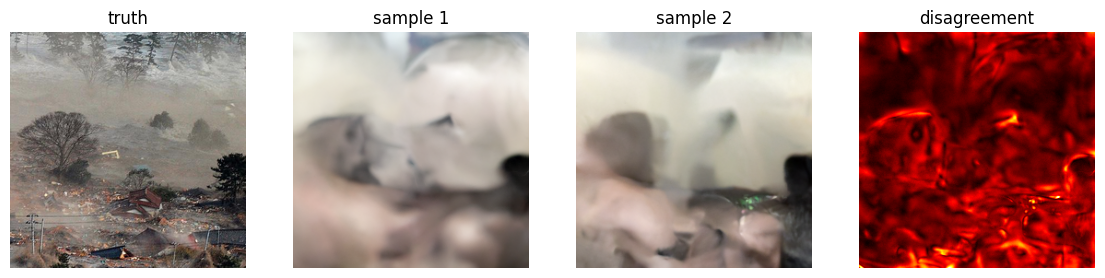

In [11]:
# which image, and what does it look like
import matplotlib.pyplot as plt
S, T = LVL[5]
r = []
for S1, T1 in zip(S, T):
    k = len(S1)
    sp = np.mean([np.abs(S1[a]-S1[b]).mean() for a in range(k) for b in range(a+1,k)])
    er = np.mean([np.abs(s-T1).mean() for s in S1])
    r.append((sp, er, sp/er))
r = np.array(r)
worst = int(np.argmin(r[:,2]))
print(f'worst: image {worst}, ratio {r[worst,2]:.3f}, spread {r[worst,0]:.2f}, error {r[worst,1]:.2f}')
print(f'others: spread {np.delete(r[:,0],worst).mean():.2f}, error {np.delete(r[:,1],worst).mean():.2f}')

fig, ax = plt.subplots(1, 4, figsize=(14,4))
ax[0].imshow(T[worst].astype('uint8')); ax[0].set_title('truth')
ax[1].imshow(S[worst,0].astype('uint8')); ax[1].set_title('sample 1')
ax[2].imshow(S[worst,1].astype('uint8')); ax[2].set_title('sample 2')
ax[3].imshow(S[worst].std(axis=0).mean(axis=2), cmap='hot'); ax[3].set_title('disagreement')
for a in ax: a.axis('off')
plt.show()

In [12]:
T8 = T[worst]; S8 = S[worst]
print(f'truth  : mean {T8.mean():.1f}  sd {T8.std():.1f}  min {T8.min():.0f}  max {T8.max():.0f}')
print(f'sample : mean {S8[0].mean():.1f}  sd {S8[0].std():.1f}')
print()
oth = [i for i in range(10) if i != worst]
print(f'other truths: mean {np.mean([T[i].mean() for i in oth]):.1f}  '
      f'sd {np.mean([T[i].std() for i in oth]):.1f}')
print()
print('per-channel truth mean:', [f'{T8[:,:,c].mean():.0f}' for c in range(3)])
print('per-channel recon mean:', [f'{S8[0][:,:,c].mean():.0f}' for c in range(3)])


truth  : mean 120.2  sd 40.6  min 0  max 255
sample : mean 165.2  sd 49.7

other truths: mean 113.8  sd 61.1

per-channel truth mean: ['126', '120', '114']
per-channel recon mean: ['174', '164', '157']


In [13]:
import glob
def mean_of(base, folder):
    fs = sorted(glob.glob(f'{base}/{folder}/*.png'))[:6]
    return np.mean([load(f).mean() for f in fs])

IN_A = '/kaggle/input/notebooks/aratisutar/prior-swap-l5'
print('truth          :', T[worst].mean().round(1))
print('FFHQ recon     :', round(mean_of(BASE, f'P_L5_{worst:05d}'), 1))
print('ImageNet recon :', round(mean_of(IN_A, f'IN_L5_{worst:05d}'), 1))

truth          : 120.2
FFHQ recon     : 161.8
ImageNet recon : nan


In [15]:
import glob
for p in glob.glob('/kaggle/input/notebooks/*/*') + glob.glob('/kaggle/input/datasets/*/*'):
    n = len(glob.glob(f'{p}/IN_L5_00008/*.png'))
    print(n, p)

0 /kaggle/input/notebooks/aratisutar/prior-swap-l5
6 /kaggle/input/notebooks/aratisutar/level-2
0 /kaggle/input/datasets/aratisutar/phasea-run3


In [16]:
print('truth          :', round(T[worst].mean(), 1))
print('FFHQ recon     :', round(mean_of(BASE, f'P_L5_{worst:05d}'), 1))
print('ImageNet recon :', round(mean_of('/kaggle/input/notebooks/aratisutar/level-2',
                                        f'IN_L5_{worst:05d}'), 1))

truth          : 120.2
FFHQ recon     : 161.8
ImageNet recon : 160.8


In [17]:
from PIL import Image
im = Image.fromarray(T[worst].astype('uint8'))
meas = np.array(im.resize((64,64), Image.BICUBIC)).astype(float)
print('truth    mean:', round(T[worst].mean(),1))
print('64x64    mean:', round(meas.mean(),1))
print('recon    mean: 161.8')
print()
print('truth percentiles:', [round(np.percentile(T[worst], q)) for q in [1,25,50,75,99]])

truth    mean: 120.2
64x64    mean: 120.2
recon    mean: 161.8

truth percentiles: [13, 95, 126, 152, 189]


In [18]:
import glob
fs = sorted(glob.glob(f'{BASE}/P_L5_{worst:05d}/*.png'))
for f in fs:
    a = load(f)
    print(f.split('/')[-1], 'mean', round(a.mean(),1), 'min', int(a.min()), 'max', int(a.max()))
print('truth file:', f'{BASE}/truth_L5_{worst:05d}.png')
t = load(f'{BASE}/truth_L5_{worst:05d}.png')
print('truth mean', round(t.mean(),1), 'min', int(t.min()), 'max', int(t.max()))

00.png mean 165.2 min 0 max 255
01.png mean 162.3 min 0 max 255
02.png mean 159.1 min 0 max 255
03.png mean 159.0 min 0 max 255
04.png mean 163.6 min 0 max 255
05.png mean 161.9 min 0 max 255
truth file: /kaggle/input/datasets/aratisutar/phasea-run3/truth_L5_00008.png
truth mean 120.2 min 0 max 255


In [20]:
# the level-5 source images, as prepared
import glob
src = sorted(glob.glob('/kaggle/input/datasets/arnaud58/landscape-pictures/*.jpg'))
src = src[::len(src)//10][:10]
from PIL import Image
im = Image.open(src[worst]).convert('RGB')
w,h = im.size; s = min(w,h)
prep = np.array(im.crop(((w-s)//2,(h-s)//2,(w+s)//2,(h+s)//2)).resize((256,256), Image.LANCZOS)).astype(float)
print('original prepared :', round(prep.mean(),1))
print('DPS truth output  :', round(T[worst].mean(),1))

original prepared : 120.3
DPS truth output  : 120.2


In [25]:
import numpy as np, glob
from PIL import Image
from math import comb
def load(p): return np.array(Image.open(p).convert('RGB')).astype(float)

FF   = '/kaggle/input/datasets/aratisutar/phasea-run3'
IN_B = '/kaggle/input/notebooks/aratisutar/level-2'

def ratio(base, folder, truth, k=6):
    fs = sorted(glob.glob(f'{base}/{folder}/*.png'))[:k]
    if len(fs) < k: return None
    S = np.stack([load(f) for f in fs])
    T = load(f'{base}/{truth}.png')
    sp = np.mean([np.abs(S[a]-S[b]).mean() for a in range(k) for b in range(a+1,k)])
    er = np.mean([np.abs(s-T).mean() for s in S])
    return sp/er

rows = []
for i in range(10):
    ff = ratio(FF, f'P_L5_{i:05d}', f'truth_L5_{i:05d}')
    inn = ratio(IN_B, f'IN_L5_{i:05d}', f'truth_IN_L5_{i:05d}')
    if ff and inn: rows.append((i, ff, inn, inn-ff))

def sign_test(d):
    n, pos = len(d), int((np.array(d) > 0).sum())
    tail = sum(comb(n,x) for x in range(max(pos, n-pos), n+1))
    return pos, n, min(1.0, 2*tail/2**n)

all_d = [r[3] for r in rows]
no8   = [r[3] for r in rows if r[0] != 8]
for lbl, d in [('all 10', all_d), ('excluding image 8', no8)]:
    pos, n, p = sign_test(d)
    print(f'{lbl:<20s} {pos}/{n} improved   mean {np.mean(d):+.3f}   p = {p:.4f}')

all 10               5/5 improved   mean +0.155   p = 0.0625
excluding image 8    4/4 improved   mean +0.188   p = 0.1250


In [26]:
IN_A = '/kaggle/input/notebooks/aratisutar/prior-swap-l5'   # images 0-4
IN_B = '/kaggle/input/notebooks/aratisutar/level-2'         # images 5-9

def imagenet_ratio(lvl, i):
    for base in (IN_A, IN_B):
        r = ratio(base, f'IN_L{lvl}_{i:05d}', f'truth_IN_L{lvl}_{i:05d}')
        if r: return r
    return None

rows = []
for i in range(10):
    ff = ratio(FF, f'P_L5_{i:05d}', f'truth_L5_{i:05d}')
    inn = imagenet_ratio(5, i)
    if ff and inn: rows.append((i, ff, inn, inn-ff))
print('found', len(rows), 'images')

all_d = [r[3] for r in rows]
no8   = [r[3] for r in rows if r[0] != 8]
for lbl, d in [('all 10', all_d), ('excluding image 8', no8)]:
    pos, n, p = sign_test(d)
    print(f'{lbl:<20s} {pos}/{n} improved   mean {np.mean(d):+.3f}   p = {p:.4f}')

found 10 images
all 10               10/10 improved   mean +0.150   p = 0.0020
excluding image 8    9/9 improved   mean +0.164   p = 0.0039
